# Inferență Bayesiană cu PyMC

Date: $56, 60, 58, 55, 57, 59, 61, 56, 58, 60$ dB.

**a)** $x$ este media eșantionului.

In [2]:
import numpy as np
import pymc as pm
import arviz as az

data = np.array([56, 60, 58, 55, 57, 59, 61, 56, 58, 60])
x = data.mean()

with pm.Model() as model:
    mu = pm.Normal("mu", mu=x, sigma=10)
    sigma = pm.HalfNormal("sigma", sigma=10)
    pm.Normal("obs", mu=mu, sigma=sigma, observed=data)

idata = pm.sample(2000, tune=1000, chains=4, random_seed=42, model=model, progressbar=False)

az.summary(idata, var_names=["mu", "sigma"], ci_prob=0.95, ci_kind="hdi")

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu, sigma]
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 3 seconds.


,mean,sd,hdi95_lb,hdi95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu,57.98,0.74,57,60,5365,4634,1.00,0.01,0.011
sigma,2.31,0.65,1.3,3.6,4908,4616,1.00,0.0096,0.012


**b)** Intervalele HDI 95%:

In [3]:
hdi = az.hdi(idata, var_names=["mu", "sigma"], prob=0.95)
hdi.to_dataset().to_dataframe().T

ci_bound,lower,upper
mu,56.581690,59.550969
sigma,1.296568,3.581975


**Histogramele distribuțiilor posterioare:**

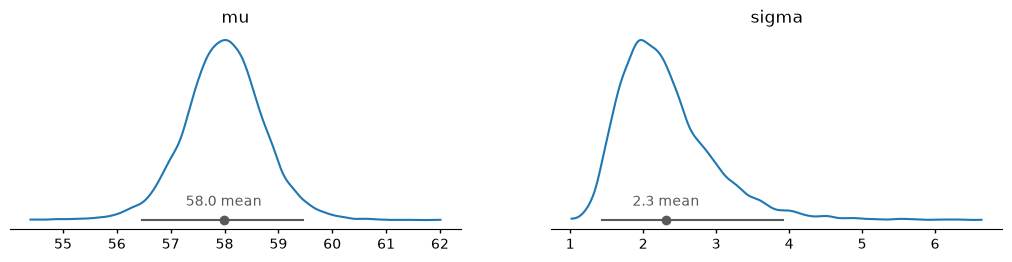

In [7]:
import arviz_plots as azp

azp.plot_dist(idata, var_names=["mu", "sigma"], kind="auto", ci_prob=0.95)